# 13 — Report figures and evaluation tables

Collects the paper-ready artifacts under `output/figures/` and `output/evals/`, built **only from the
stored result csvs** in `data/processed/` — no model is fit here, nothing is recomputed from raw files,
and no result number is typed in by hand (the asserts below check recomputed aggregates against the
documented headline values instead). Filenames carry the cohort/grain/horizon they describe
(`c110`, `h1`/`h6`, `national`) so an artifact is identifiable without opening it.

Two scope rules, decided 2026-07-30:

- **Descriptive charts show all 96 months including FY 2025-26** — the sealed year is sealed for
  *modelling* (training/validation/calibration), not for drawing the national series; it is shaded and
  labelled in every trend figure. This matches how notebook 02 reported the headline table.
- **Existing result csvs are not copied or renamed into `output/`** — `data/processed/` stays the single
  source of truth; the manifest written at the end points each figure/table at its source instead.

In [1]:
import pandas as pd                          # tables: csv loading, groupby aggregation
import numpy as np                           # arithmetic guards (np.where) and rounding
import matplotlib.pyplot as plt              # plotting; runs headless, figures saved to png
from pathlib import Path

PROC = Path("../data/processed")
FIGS = Path("../output/figures"); FIGS.mkdir(parents=True, exist_ok=True)
EVALS = Path("../output/evals"); EVALS.mkdir(parents=True, exist_ok=True)

COVID = pd.Timestamp("2020-03-01")           # declared regime break (unchanged everywhere)
TEST_START = pd.Timestamp("2025-04-01")      # sealed test year - shaded in charts, never modelled

panel = pd.read_csv(PROC / "rtt_incomplete_panel.csv", parse_dates=["month"])
assert panel.shape == (343441, 8), panel.shape   # a regenerated or corrupted panel csv trips this

manifest = []                                # (artifact, source, what it shows) - written at the end
def save_fig(fig, name, source, what):
    fig.savefig(FIGS / name, dpi=150, bbox_inches="tight")
    manifest.append((f"figures/{name}", source, what))
def save_eval(df, name, source, what):
    df.to_csv(EVALS / name, index=False)
    manifest.append((f"evals/{name}", source, what))

# national monthly series: sum over every provider x specialty row in the month
nat = panel.groupby("month")[["total_waiting", "gt18", "gt52"]].sum().reset_index()
nat["pct_gt18"] = nat["gt18"] / nat["total_waiting"]   # denominator: that month's national list
nat["pct_gt52"] = nat["gt52"] / nat["total_waiting"]
nat["era"] = np.where(nat["month"] < COVID, "pre_covid", "post_covid")
assert nat["era"].value_counts().to_dict() == {"post_covid": 73, "pre_covid": 23}
print(len(nat), "months,", panel["provider_code"].nunique(), "providers,",
      panel["tfunc_code"].nunique(), "specialties")

96 months, 651 providers, 24 specialties


## National trend figures

The two headline charts: the waiting-list level and the long-wait shares, with the regime break and the
sealed year marked so a reader sees at a glance which months the models were allowed to touch. Level and
shares stay in **separate figures** — a secondary axis was proposed externally and rejected (two y-scales
on one chart invite misreading the crossing points).

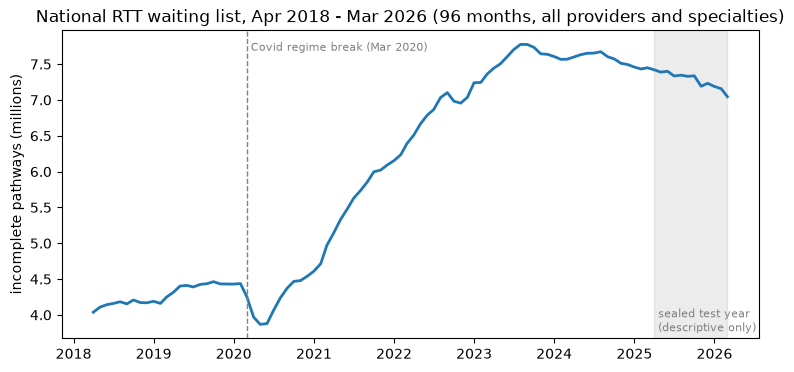

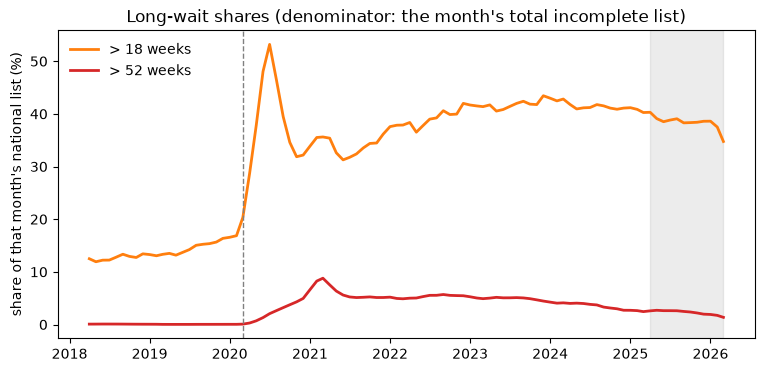

In [2]:
# Goal: fig_national_trend.png and fig_national_longwait_shares.png.
def mark_eras(ax):                           # regime break line + shaded sealed year, shared by both charts
    ax.axvline(COVID, color="gray", lw=1, ls="--")
    ax.axvspan(TEST_START, nat["month"].max(), color="gray", alpha=0.15)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(nat["month"], nat["total_waiting"] / 1e6, color="C0", lw=2)
mark_eras(ax)
ax.text(COVID, ax.get_ylim()[1] * 0.98, " Covid regime break (Mar 2020)", va="top", fontsize=8, color="gray")
ax.text(TEST_START, ax.get_ylim()[0] + 0.1, " sealed test year\n (descriptive only)", fontsize=8, color="gray")
ax.set_ylabel("incomplete pathways (millions)")
ax.set_title("National RTT waiting list, Apr 2018 - Mar 2026 (96 months, all providers and specialties)")
save_fig(fig, "fig_national_trend.png", "rtt_incomplete_panel.csv", "national waiting-list level by month")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(nat["month"], nat["pct_gt18"] * 100, color="C1", lw=2, label="> 18 weeks")
ax.plot(nat["month"], nat["pct_gt52"] * 100, color="C3", lw=2, label="> 52 weeks")
mark_eras(ax)
ax.set_ylabel("share of that month's national list (%)")
ax.set_title("Long-wait shares (denominator: the month's total incomplete list)")
ax.legend(frameon=False)
save_fig(fig, "fig_national_longwait_shares.png", "rtt_incomplete_panel.csv", "monthly >18w and >52w shares")
plt.show()

## Pre/post-Covid evaluation tables

Four grains: national, per specialty, per provider (hospital), per provider x specialty (department within
a hospital). Two different rate constructions, each named in its columns:

- the **national** table averages the *monthly* shares (matching the summary doc's headline table, whose
  denominator is each month's list) — and asserts the recomputed values equal the documented ones;
- the specialty/provider/cell tables use **era-aggregate** rates, `sum(gt18) / sum(total_waiting)` over all
  patient-months in the era — the right construction when a series has months of very different size
  (the externally proposed mean of row-level percentages would weigh a 12-patient list like an 18,000-patient one).

In [3]:
# Goal: eval_national_pre_post.csv, asserted against the documented headline numbers.
natsum = nat.groupby("era").agg(n_months=("month", "size"),
                                mean_waiting=("total_waiting", "mean"),
                                mean_pct_gt18=("pct_gt18", "mean"),   # mean of monthly shares -
                                mean_pct_gt52=("pct_gt52", "mean"))   # matches the doc's headline table
natsum = natsum.reindex(["pre_covid", "post_covid"]).reset_index()

pre, post = natsum.iloc[0], natsum.iloc[1]
assert round(pre["mean_waiting"] / 1e3) == 4283, pre["mean_waiting"]    # documented 4,283,000
assert round(post["mean_waiting"] / 1e3) == 6574, post["mean_waiting"]  # documented 6,574,296
assert round(pre["mean_pct_gt18"] * 100, 1) == 13.9                     # documented 13.9%
assert round(post["mean_pct_gt18"] * 100, 1) == 38.8                    # documented 38.8%
assert round(pre["mean_pct_gt52"] * 100, 2) == 0.05                     # documented 0.05%
assert round(post["mean_pct_gt52"] * 100, 2) == 4.11                    # documented 4.11%
# any of these firing means the panel csv no longer reproduces the summary doc's headline table

save_eval(natsum, "eval_national_pre_post.csv", "rtt_incomplete_panel.csv",
          "era means of the monthly national series (pre: 23 months, post: 73)")
print(natsum.round(4).to_string(index=False))

       era  n_months  mean_waiting  mean_pct_gt18  mean_pct_gt52
 pre_covid        23  4283000.4783         0.1389         0.0005
post_covid        73  6574295.7808         0.3876         0.0411


In [4]:
# Goal: the three finer pre/post tables with era-aggregate rates.
panel["era"] = np.where(panel["month"] < COVID, "pre_covid", "post_covid")

def era_table(keys):                         # one construction for all three grains
    m = panel.groupby(keys + ["month", "era"])[["total_waiting", "gt18", "gt52"]].sum().reset_index()
    g = m.groupby(keys + ["era"]).agg(n_months=("month", "size"),
                                      mean_monthly_waiting=("total_waiting", "mean"),
                                      tw_sum=("total_waiting", "sum"),
                                      gt18_sum=("gt18", "sum"),
                                      gt52_sum=("gt52", "sum")).reset_index()
    # era-aggregate rates; denominator: the era's summed patient-months (tw_sum).
    # tw_sum == 0 is real - providers/cells that reported only empty lists in an era - so guard it
    g["pct_gt18_era"] = np.where(g["tw_sum"] > 0, g["gt18_sum"] / g["tw_sum"], np.nan)
    g["pct_gt52_era"] = np.where(g["tw_sum"] > 0, g["gt52_sum"] / g["tw_sum"], np.nan)
    return g.drop(columns=["gt18_sum", "gt52_sum"])

# trust names for readability; only the 193 ODS public trusts have one - independents stay NaN
names = pd.read_csv(PROC / "rtt_kh03_canonical_panel.csv",
                    usecols=["provider_code", "trust_name"]).drop_duplicates()

spec = era_table(["tfunc_code"])
prov = era_table(["provider_code"]).merge(names, on="provider_code", how="left")
cell = era_table(["provider_code", "tfunc_code"]).merge(names, on="provider_code", how="left")
save_eval(spec, "eval_specialty_pre_post.csv", "rtt_incomplete_panel.csv",
          "per-specialty era summary (24 specialties)")
save_eval(prov, "eval_provider_pre_post.csv", "rtt_incomplete_panel.csv",
          "per-provider era summary (651 providers)")
save_eval(cell, "eval_provider_specialty_pre_post.csv", "rtt_incomplete_panel.csv",
          "per (provider, specialty) era summary - departments within hospitals")
print(spec.shape, prov.shape, cell.shape)
print(spec[spec["tfunc_code"] == "C_110"].round(4).to_string(index=False))

(43, 7) (1079, 8) (9407, 9)
tfunc_code        era  n_months  mean_monthly_waiting   tw_sum  pct_gt18_era  pct_gt52_era
     C_110 post_covid        73           762470.7671 55660366        0.4363        0.0595
     C_110  pre_covid        23           509065.3478 11708503        0.1704        0.0013


## Forecasting figures and stability tables

The horizon chart reads the two stored horizon csvs (09 and 12) directly — persistence vs its closest
challenger (drift, full history) and seasonal at each grain. The y-scales differ by ~30x between grains,
so each grain gets its own panel; comparing across panels is meaningless by construction.

Two stability views of the MAE-153 anchor, both sliced from the stored 04 forecasts: by origin month
(is the result driven by one bad month?) and by provider (who is hard to forecast?).

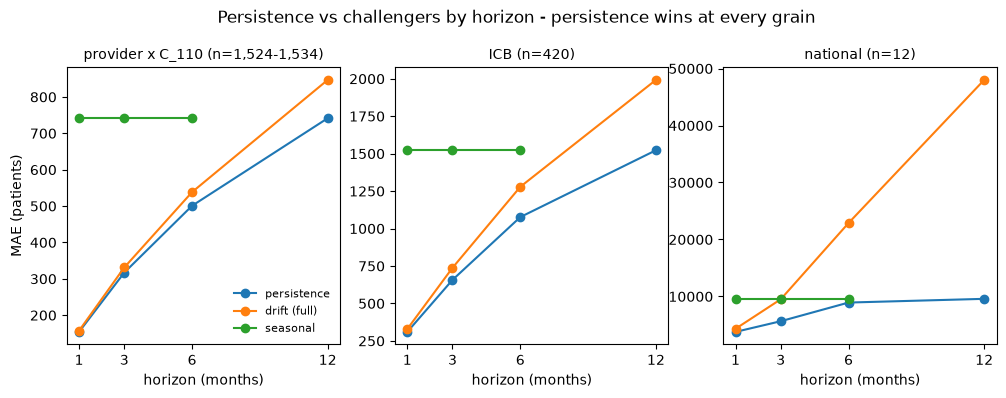

In [5]:
# Goal: fig_c110_horizon_mae_by_grain.png - persistence vs challengers at provider / ICB / national grain.
hz = pd.read_csv(PROC / "val_horizons_c110.csv")
hzc = pd.read_csv(PROC / "val_horizons_coarse_c110.csv")
assert hz.shape == (23, 6) and hzc.shape == (30, 7), (hz.shape, hzc.shape)

grains = [("provider", hz, "provider x C_110 (n=1,524-1,534)"),
          ("icb", hzc[hzc["grain"] == "icb"], "ICB (n=420)"),
          ("national", hzc[hzc["grain"] == "national"], "national (n=12)")]
series = [("persistence", "-", "C0"), ("drift", "full", "C1"), ("seasonal", "-", "C2")]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (grain, d, label) in zip(axes, grains):
    for model, regime, color in series:
        s = d[(d["model"] == model) & (d["regime"] == regime)].sort_values("h")
        ax.plot(s["h"], s["mae"], marker="o", color=color, label=f"{model} ({regime})" if regime != "-" else model)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("horizon (months)"); ax.set_xticks([1, 3, 6, 12])
axes[0].set_ylabel("MAE (patients)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Persistence vs challengers by horizon - persistence wins at every grain", y=1.04)
save_fig(fig, "fig_c110_horizon_mae_by_grain.png", "val_horizons_c110.csv + val_horizons_coarse_c110.csv",
         "MAE by horizon and grain, persistence vs drift-full vs seasonal")
plt.show()

In [6]:
# Goal: eval_c110_persistence_mae_by_month_h1.csv - is the MAE-153 result stable across the validation year?
vf = pd.read_csv(PROC / "val_forecasts_c110_public_clients.csv", parse_dates=["month"])
assert len(vf) == 1407, len(vf)              # must be the exact 04 validation rows
vf["ae_naive"] = (vf["target"] - vf["pred_naive"]).abs()
assert round(vf["ae_naive"].mean()) == 153   # the documented anchor; a changed csv trips this

by_month = vf.groupby("month").agg(n=("ae_naive", "size"), mae_naive=("ae_naive", "mean")).reset_index()
save_eval(by_month, "eval_c110_persistence_mae_by_month_h1.csv", "val_forecasts_c110_public_clients.csv",
          "persistence MAE per forecast-origin month, FY 2024-25")
print(by_month.round(1).to_string(index=False))

     month   n  mae_naive
2024-04-01 127      131.2
2024-05-01 128      127.2
2024-06-01 128      140.3
2024-07-01 128      150.5
2024-08-01 128      123.3
2024-09-01 128      142.4
2024-10-01 128      152.1
2024-11-01 128      221.9
2024-12-01 128      168.4
2025-01-01 128      129.9
2025-02-01 128      200.9


C:\Users\heave\AppData\Local\Temp\ipykernel_11700\4152640594.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(by_month.round(1).to_string(index=False))


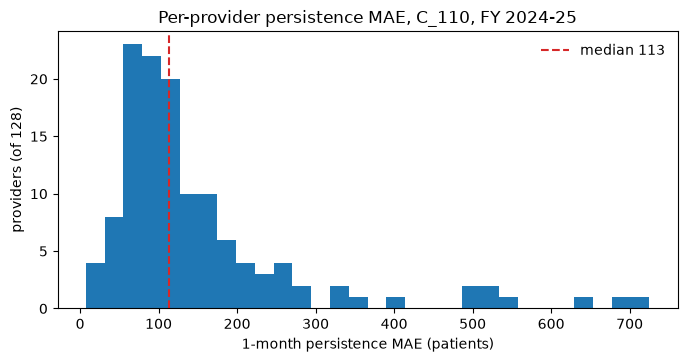

provider_code  n  mae_naive                                       trust_name
          RXC 11      725.2                 EAST SUSSEX HEALTHCARE NHS TRUST
          RDR 11      693.3            SUSSEX COMMUNITY NHS FOUNDATION TRUST
          R0A 11      634.4       MANCHESTER UNIVERSITY NHS FOUNDATION TRUST
          R1D 11      534.6            SHROPSHIRE COMMUNITY HEALTH NHS TRUST
          RYR 11      516.3 UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST


In [7]:
# Goal: fig + eval - how the pooled MAE 153 distributes across the providers scored in FY 2024-25.
per_prov = (vf.groupby("provider_code").agg(n=("ae_naive", "size"), mae_naive=("ae_naive", "mean"))
            .reset_index().merge(names, on="provider_code", how="left"))
assert len(per_prov) == 128, len(per_prov)   # the 04 cohort holds 130 providers but two file no
# FY 2024-25 rows - the same 128 clients notebook 11 scores; a changed forecasts csv trips this
save_eval(per_prov.sort_values("mae_naive", ascending=False), "eval_c110_provider_mae_h1.csv",
          "val_forecasts_c110_public_clients.csv", "per-provider 1-month persistence MAE, FY 2024-25")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(per_prov["mae_naive"], bins=30, color="C0")
ax.axvline(per_prov["mae_naive"].median(), color="C3", ls="--", lw=1.5,
           label=f"median {per_prov['mae_naive'].median():.0f}")
ax.set_xlabel("1-month persistence MAE (patients)")
ax.set_ylabel("providers (of 128)")
ax.set_title("Per-provider persistence MAE, C_110, FY 2024-25")
ax.legend(frameon=False)
save_fig(fig, "fig_c110_provider_mae_h1.png", "val_forecasts_c110_public_clients.csv",
         "distribution of per-provider 1-month persistence MAE")
plt.show()
print(per_prov.sort_values("mae_naive", ascending=False).head(5).round(1).to_string(index=False))

## Agent tables, stress test and figure

Everything below **slices the stored decisions** (`agent_decisions_h6_c110.csv`) — recomputing decisions
here would create a second implementation that could silently drift from notebook 10's. The two rule
sets are named by what they decide — the **capacity** rules (EXPAND_CAPACITY) and the **redistribution**
rules (within-ICB OUT/IN) — and are keyed `v1`/`v2` in the stored csv columns.

Stress test: the 18 origin months (Apr 2023 – Sep 2024) split into three consecutive **disjoint** 6-month
windows that partition the simulation exactly (asserted) — a declared, untuned split; the externally
proposed overlapping windows would double-count rows. If the redistribution rule is stable, each window
should show the same shape: OUT median pressure far above IN, OUT preceding the largest realized changes.

In [8]:
# Goal: per-provider and per-ICB decision tables + the three-window stress test.
dec = pd.read_csv(PROC / "agent_decisions_h6_c110.csv", parse_dates=["month"])
assert dec.shape == (2337, 17), dec.shape
assert dec["decision_v2"].value_counts().to_dict() == {
    "STATUS_QUO": 1775, "REDISTRIBUTE_OUT": 457, "REDISTRIBUTE_IN": 105}   # the stored 10 counts

prov_dec = (dec.groupby(["provider_code", "trust_name", "icb_code"])
            [["decision", "decision_v2"]]
            .agg(lambda s: s.value_counts().to_dict())   # counts per class, one dict column per rule set
            .reset_index())
prov_dec = pd.concat([prov_dec.drop(columns=["decision", "decision_v2"]),
                      pd.json_normalize(prov_dec["decision"]).fillna(0).astype(int).add_prefix("v1_"),
                      pd.json_normalize(prov_dec["decision_v2"]).fillna(0).astype(int).add_prefix("v2_")], axis=1)
assert len(prov_dec) == 132, len(prov_dec)   # the simulation covers 132 providers - an earlier
# manifest description wrongly said 150; this assert pins the recount
save_eval(prov_dec, "eval_c110_agent_provider_h6.csv", "agent_decisions_h6_c110.csv",
          "capacity (v1_) and redistribution (v2_) decision counts per provider (132 providers)")

# per-ICB: provider count, redistribution counts, connectivity = share of OUT months with >= 1 IN
# in the same ICB-month
icb = dec.groupby("icb_code")["decision_v2"].value_counts().unstack(fill_value=0).reset_index()
icb = icb.merge(dec.groupby("icb_code")["provider_code"].nunique().rename("n_providers").reset_index(),
                on="icb_code")
senders = dec[dec["decision_v2"] == "REDISTRIBUTE_OUT"]
slots = dec[dec["decision_v2"] == "REDISTRIBUTE_IN"][["month", "icb_code"]].drop_duplicates()
m = senders.merge(slots, on=["month", "icb_code"], how="left", indicator=True)
conn = (m.assign(has_receiver=m["_merge"] == "both")
        .groupby("icb_code")["has_receiver"].mean().rename("out_share_with_receiver").reset_index())
icb = icb.merge(conn, on="icb_code", how="left")   # ICBs with zero OUT months get NaN - nothing to connect
save_eval(icb, "eval_c110_agent_icb_h6.csv", "agent_decisions_h6_c110.csv",
          "redistribution decision counts, provider count and in-ICB receiver share per ICB")
assert round((m["_merge"] == "both").mean(), 3) == 0.136   # the documented 13.6% of 457 OUT rows

WINDOWS = [("2023-04 to 2023-09", "2023-04-01", "2023-09-01"),   # three consecutive 6-month
           ("2023-10 to 2024-03", "2023-10-01", "2024-03-01"),   # origin windows - declared split,
           ("2024-04 to 2024-09", "2024-04-01", "2024-09-01")]   # not tuned
rows = []
for label, lo, hi in WINDOWS:
    w = dec[(dec["month"] >= lo) & (dec["month"] <= hi)]
    for cls, grp in w.groupby("decision_v2"):
        rows.append({"window": label, "decision_v2": cls, "n": len(grp),
                     "median_pressure": grp["pressure_score"].median(),
                     "median_realized_change": grp["realized_change"].median()})
stress = pd.DataFrame(rows)
assert stress["n"].sum() == 2337             # the windows must partition all stored decisions exactly
save_eval(stress, "eval_c110_agent_stress_h6.csv", "agent_decisions_h6_c110.csv",
          "redistribution class sizes and medians in three consecutive 6-month origin windows")
print(stress.round(3).to_string(index=False))

            window      decision_v2   n  median_pressure  median_realized_change
2023-04 to 2023-09  REDISTRIBUTE_IN  35            0.179                    29.0
2023-04 to 2023-09 REDISTRIBUTE_OUT 154            0.764                    17.5
2023-04 to 2023-09       STATUS_QUO 596            0.463                    67.5
2023-10 to 2024-03  REDISTRIBUTE_IN  33            0.181                   -36.0
2023-10 to 2024-03 REDISTRIBUTE_OUT 164            0.717                    44.5
2023-10 to 2024-03       STATUS_QUO 579            0.461                    -7.0
2024-04 to 2024-09  REDISTRIBUTE_IN  37            0.198                   -37.0
2024-04 to 2024-09 REDISTRIBUTE_OUT 139            0.673                   181.0
2024-04 to 2024-09       STATUS_QUO 600            0.491                     7.5


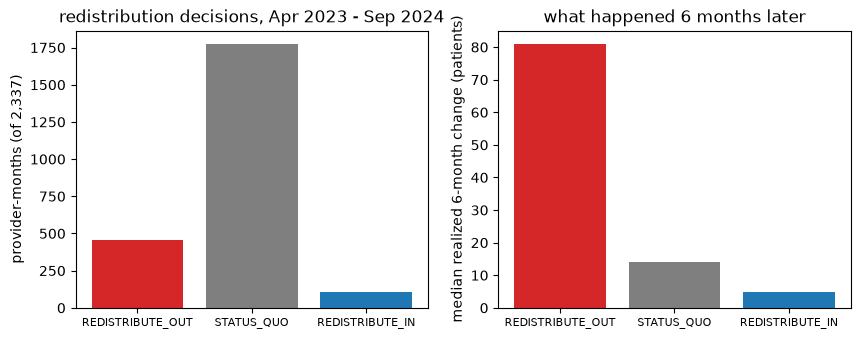

In [9]:
# Goal: fig_c110_agent_v2_h6.png - what the redistribution classes are and what actually happened to them.
cls_order = ["REDISTRIBUTE_OUT", "STATUS_QUO", "REDISTRIBUTE_IN"]
counts = dec["decision_v2"].value_counts().reindex(cls_order)
med = dec.groupby("decision_v2")["realized_change"].median().reindex(cls_order)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(cls_order, counts.values, color=["C3", "C7", "C0"])
axes[0].set_ylabel("provider-months (of 2,337)")
axes[0].set_title("redistribution decisions, Apr 2023 - Sep 2024")
axes[1].bar(cls_order, med.values, color=["C3", "C7", "C0"])
axes[1].set_ylabel("median realized 6-month change (patients)")
axes[1].set_title("what happened 6 months later")
for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
save_fig(fig, "fig_c110_agent_v2_h6.png", "agent_decisions_h6_c110.csv",
         "redistribution class sizes and median realized 6-month change per class")
plt.show()

## Federated learning figure

Straight from `fl_summary_c110.csv`: every model in both regimes against the persistence line. The chart
is the FL story in one look — level-FedAvg far right, delta-FedAvg on the line with pooled.

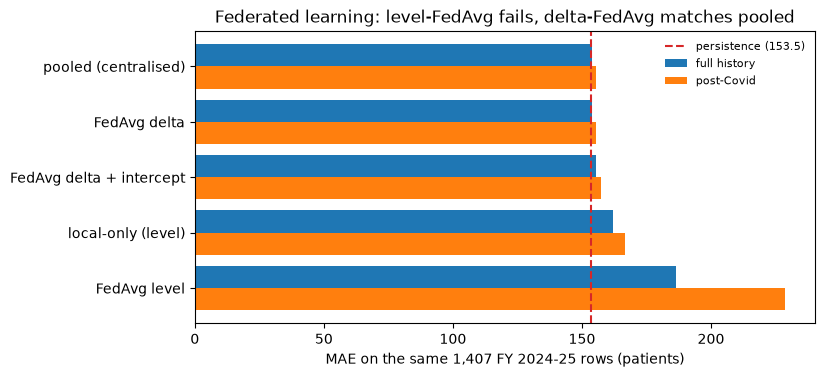

In [10]:
# Goal: fig_c110_fl_models_h1.png - MAE per FL model and regime vs the persistence baseline.
fl = pd.read_csv(PROC / "fl_summary_c110.csv")
assert fl.shape == (11, 5), fl.shape
naive = fl.loc[fl["model"] == "naive persistence", "mae"].iloc[0]

order = ["pooled", "fedavg-delta", "fedavg-delta+local-a", "local-only", "fedavg"]
labels = ["pooled (centralised)", "FedAvg delta", "FedAvg delta + intercept",   # readable names for
          "local-only (level)", "FedAvg level"]                                 # the stored csv keys
full = fl[fl["regime"] == "full"].set_index("model").loc[order, "mae"]
post = fl[fl["regime"] == "post"].set_index("model").loc[order, "mae"]

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(order))
ax.barh(y - 0.2, full.values, height=0.4, color="C0", label="full history")
ax.barh(y + 0.2, post.values, height=0.4, color="C1", label="post-Covid")
ax.axvline(naive, color="C3", ls="--", lw=1.5, label=f"persistence ({naive:.1f})")
ax.set_yticks(y, labels); ax.invert_yaxis()
ax.set_xlabel("MAE on the same 1,407 FY 2024-25 rows (patients)")
ax.set_title("Federated learning: level-FedAvg fails, delta-FedAvg matches pooled")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_c110_fl_models_h1.png", "fl_summary_c110.csv", "MAE per FL model and regime vs persistence")
plt.show()

## Cross-model comparison figures (linear vs neural, regime effect, dataset size)

Three questions the figures above leave open, each answered from a stored csv without recomputing
anything. Every direct linear-vs-neural comparison comes from `fl_neural_summary.csv` alone, because
notebook 16 rescored **all** models — persistence included — on the identical eligible windows
(C_110: 1,401 of the standard 1,407 rows); mixing it with the other csvs would compare different
denominators. The regime-effect chart is the one place two csvs share a figure, and there each series
compares only itself across regimes, never one family against the other.

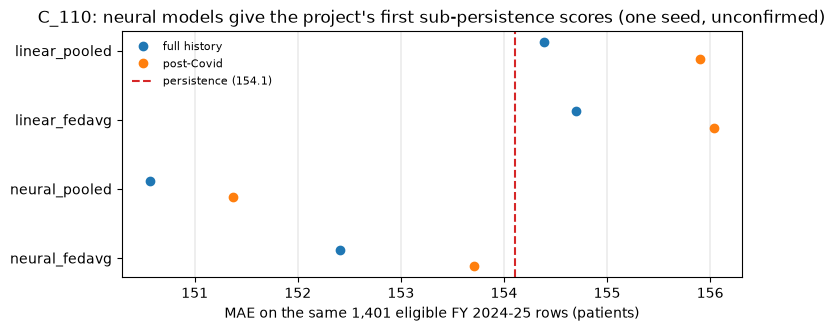

In [11]:
# Goal: fig_c110_fl_linear_vs_neural_h1.png - the four trained model families vs persistence at C_110.
nn = pd.read_csv(PROC / "fl_neural_summary.csv")
assert nn.shape == (207, 7), nn.shape        # 23 specialties x (persistence + 4 models x 2 regimes)
c110 = nn[nn["tfunc_code"] == "C_110"]
assert set(c110["n"]) == {1401}              # every C_110 score must sit on the same eligible windows
pers = c110.loc[c110["model"] == "persistence", "mae"].iloc[0]
assert round(pers, 1) == 154.1               # the documented notebook-16 anchor; a changed csv trips this

order = ["linear_pooled", "linear_fedavg", "neural_pooled", "neural_fedavg"]
full = c110[c110["regime"] == "full"].set_index("model").loc[order, "mae"]
post = c110[c110["regime"] == "post"].set_index("model").loc[order, "mae"]

# dot markers, not bars: the interesting spread is ~5 patients on a ~150 scale, and a bar chart
# could only show it with a truncated axis, which visually inflates the differences
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(order))
ax.plot(full.values, y - 0.12, "o", color="C0", label="full history")
ax.plot(post.values, y + 0.12, "o", color="C1", label="post-Covid")
ax.axvline(pers, color="C3", ls="--", lw=1.5, label=f"persistence ({pers:.1f})")
ax.set_yticks(y, order); ax.invert_yaxis()
ax.grid(axis="x", lw=0.3)
ax.set_xlabel("MAE on the same 1,401 eligible FY 2024-25 rows (patients)")
ax.set_title("C_110: neural models give the project's first sub-persistence scores (one seed, unconfirmed)")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_c110_fl_linear_vs_neural_h1.png", "fl_neural_summary.csv",
         "linear vs neural FL at C_110, both regimes, identical eligible rows")
plt.show()

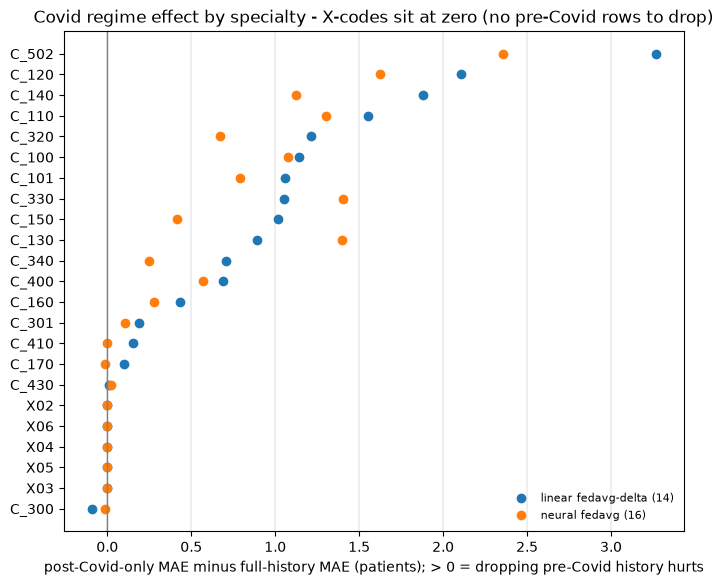

In [12]:
# Goal: fig_fl_covid_regime_effect_h1.png - what discarding pre-Covid training history costs, per specialty.
# Each swing (post-only MAE minus full-history MAE) is computed inside its own csv on its own fixed
# validation rows - no linear number is ever compared against a neural number here, only regime
# against regime within one model family.
scale = pd.read_csv(PROC / "fl_scaleup_by_specialty.csv")
assert scale.shape == (24, 22), scale.shape
scale = scale[scale["n_val"] > 0].set_index("tfunc_code")   # X01 has zero validation rows in this pool
lin_swing = scale["fedavg_delta_post_mae"] - scale["fedavg_delta_full_mae"]
neu = nn[nn["model"] == "neural_fedavg"].pivot(index="tfunc_code", columns="regime", values="mae")
neu_swing = neu["post"] - neu["full"]
assert set(lin_swing.index) == set(neu_swing.index)         # 14 and 16 must score the same 23 specialties

lin_swing = lin_swing.sort_values(ascending=False)
neu_swing = neu_swing.reindex(lin_swing.index)
fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(len(lin_swing))
ax.plot(lin_swing.values, y, "o", color="C0", label="linear fedavg-delta (14)")
ax.plot(neu_swing.values, y, "o", color="C1", label="neural fedavg (16)")
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(y, lin_swing.index); ax.invert_yaxis()
ax.grid(axis="x", lw=0.3)
ax.set_xlabel("post-Covid-only MAE minus full-history MAE (patients); > 0 = dropping pre-Covid history hurts")
ax.set_title("Covid regime effect by specialty - X-codes sit at zero (no pre-Covid rows to drop)")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_fl_covid_regime_effect_h1.png", "fl_scaleup_by_specialty.csv + fl_neural_summary.csv",
         "per-specialty cost of training on post-Covid data only, linear and neural FedAvg")
plt.show()

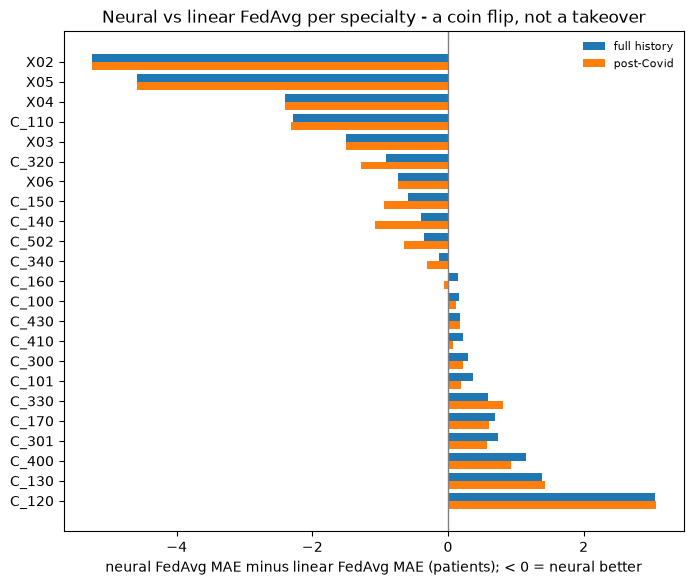

In [13]:
# Goal: fig_fl_neural_gap_by_specialty_h1.png - where neural beats linear, specialty by specialty.
wf = nn[nn["regime"] == "full"].pivot(index="tfunc_code", columns="model", values="mae")
wp = nn[nn["regime"] == "post"].pivot(index="tfunc_code", columns="model", values="mae")
gap_full = (wf["neural_fedavg"] - wf["linear_fedavg"]).sort_values()
gap_post = (wp["neural_fedavg"] - wp["linear_fedavg"]).reindex(gap_full.index)
assert (gap_full < 0).sum() == 11 and (gap_post < 0).sum() == 12   # documented win counts (of 23
# scored specialties); a rerun of 16 that shifted any specialty across zero trips this

fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(len(gap_full))
ax.barh(y - 0.2, gap_full.values, height=0.4, color="C0", label="full history")
ax.barh(y + 0.2, gap_post.values, height=0.4, color="C1", label="post-Covid")
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(y, gap_full.index); ax.invert_yaxis()
ax.set_xlabel("neural FedAvg MAE minus linear FedAvg MAE (patients); < 0 = neural better")
ax.set_title("Neural vs linear FedAvg per specialty - a coin flip, not a takeover")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_fl_neural_gap_by_specialty_h1.png", "fl_neural_summary.csv",
         "per-specialty MAE gap, neural minus linear FedAvg, both regimes")
plt.show()

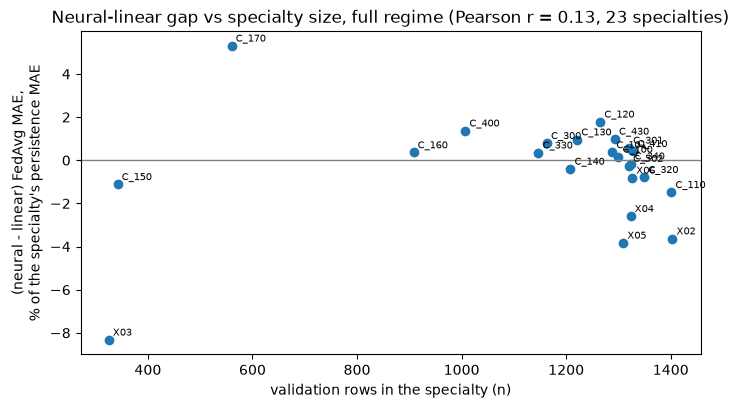

r = 0.128; specialties sorted by relative gap (% of persistence MAE):
tfunc_code
X03     -8.32
X05     -3.83
X02     -3.63
X04     -2.60
C_110   -1.48
C_150   -1.11
X06     -0.82
C_320   -0.78
C_140   -0.40
C_502   -0.27
C_340   -0.16
C_100    0.15
C_330    0.35
C_160    0.36
C_101    0.36
C_410    0.42
C_301    0.57
C_300    0.79
C_130    0.96
C_430    0.99
C_400    1.37
C_120    1.78
C_170    5.30


In [14]:
# Goal: fig_fl_neural_gap_vs_size_h1.png - is dataset size what separates neural winners from losers?
# Training-row counts were never stored; the stored size measures are validation rows (n) and client
# count (n_clients), which grow together - n is used here. The gap is scaled by each specialty's own
# persistence MAE because raw MAE spans 13 to 172 patients across specialties.
pers_all = nn[nn["model"] == "persistence"].set_index("tfunc_code")
rel = (gap_full / pers_all["mae"].reindex(gap_full.index)) * 100
size = pers_all["n"].reindex(gap_full.index)
r = np.corrcoef(size, rel)[0, 1]             # computed, not asserted - the chart reports whatever it is

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(size, rel, color="C0")
for code in rel.index:                       # label every point - 23 specialties fit without collision
    ax.annotate(code, (size[code], rel[code]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="gray", lw=1)
ax.set_xlabel("validation rows in the specialty (n)")
ax.set_ylabel("(neural - linear) FedAvg MAE,\n% of the specialty's persistence MAE")
ax.set_title(f"Neural-linear gap vs specialty size, full regime (Pearson r = {r:.2f}, 23 specialties)")
save_fig(fig, "fig_fl_neural_gap_vs_size_h1.png", "fl_neural_summary.csv",
         "relative neural-linear gap vs specialty validation size, full regime")
plt.show()
print(f"r = {r:.3f}; specialties sorted by relative gap (% of persistence MAE):")
print(rel.sort_values().round(2).to_string())

## Sealed-year figures and the results list

The one-shot (17, run once 2026-07-30) stored its scores in `sealed_year_eval.csv`; these cells chart
it — the C_110 verdict, the per-specialty gaps, and the year drift — and then generate
`output/RESULTS.md`, the headline-results list. Every number in that list is computed here from a
stored csv at build time; nothing is typed from memory, and the sealed year itself is never re-read
(the csv is 17's one and only reading of it).

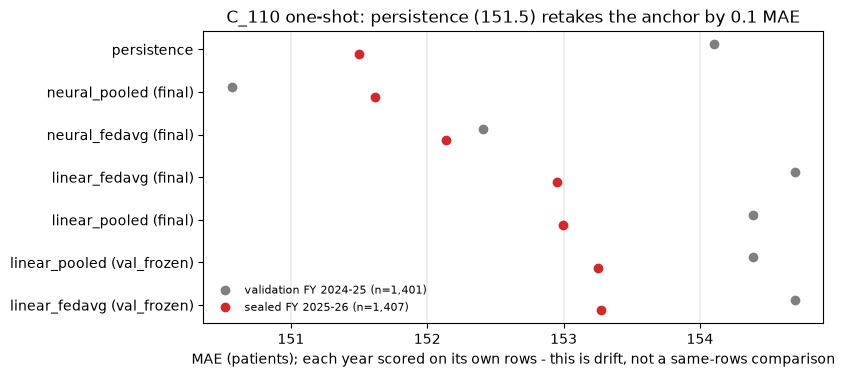

In [15]:
# Goal: fig_c110_sealed_one_shot_h1.png - the one-shot verdict at the anchor, both years side by side.
sealed = pd.read_csv(PROC / "sealed_year_eval.csv")
assert sealed.shape == (161, 8), sealed.shape     # 23 specialties x 7 model rows; a regenerated csv trips this
sc = sealed[sealed["tfunc_code"] == "C_110"].copy()
sp = sc.loc[sc["model"] == "persistence", "mae"].iloc[0]
assert round(sp, 1) == 151.5                      # the stored one-shot persistence anchor

sc["label"] = sc["model"] + np.where(sc["train_cut"] == "-", "", " (" + sc["train_cut"] + ")")
sc = sc.sort_values("mae")
assert sc.iloc[0]["model"] == "persistence"       # the verdict itself: persistence retook the anchor

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(sc))
ax.plot(sc["val_mae_full"], y - 0.12, "o", color="C7", label="validation FY 2024-25 (n=1,401)")
ax.plot(sc["mae"], y + 0.12, "o", color="C3", label="sealed FY 2025-26 (n=1,407)")
ax.set_yticks(y, sc["label"]); ax.invert_yaxis()
ax.grid(axis="x", lw=0.3)
ax.set_xlabel("MAE (patients); each year scored on its own rows - this is drift, not a same-rows comparison")
ax.set_title(f"C_110 one-shot: persistence ({sp:.1f}) retakes the anchor by 0.1 MAE")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_c110_sealed_one_shot_h1.png", "sealed_year_eval.csv",
         "C_110 validation vs sealed-year MAE for every model, one-shot verdict")
plt.show()

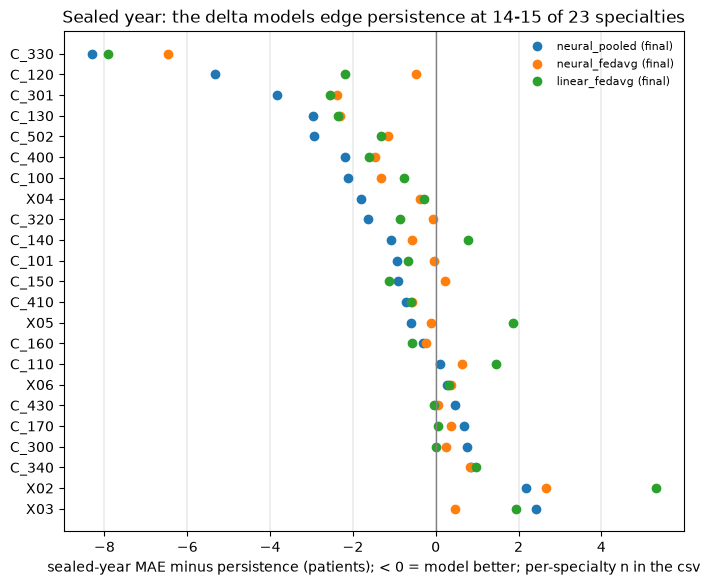

In [16]:
# Goal: fig_sealed_gap_by_specialty_h1.png - where each final-cut model beats persistence on the sealed year.
sp_all = sealed[sealed["model"] == "persistence"].set_index("tfunc_code")["mae"]
gaps = {}
for mname in ["neural_pooled", "neural_fedavg", "linear_fedavg"]:
    s = sealed[(sealed["model"] == mname) & (sealed["train_cut"] == "final")].set_index("tfunc_code")["mae"]
    gaps[mname] = s - sp_all.loc[s.index]
assert (gaps["neural_pooled"] < 0).sum() == 15 and (gaps["neural_fedavg"] < 0).sum() == 14 \
    and (gaps["linear_fedavg"] < 0).sum() == 14   # the stored one-shot win counts (of 23 scored
# specialties); a regenerated sealed csv trips this

order_idx = gaps["neural_pooled"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 6.5))
for mname, color in [("neural_pooled", "C0"), ("neural_fedavg", "C1"), ("linear_fedavg", "C2")]:
    g = gaps[mname].reindex(order_idx)
    ax.plot(g.values, np.arange(len(g)), "o", color=color, label=f"{mname} (final)")
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(np.arange(len(order_idx)), order_idx); ax.invert_yaxis()
ax.grid(axis="x", lw=0.3)
ax.set_xlabel("sealed-year MAE minus persistence (patients); < 0 = model better; per-specialty n in the csv")
ax.set_title("Sealed year: the delta models edge persistence at 14-15 of 23 specialties")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_sealed_gap_by_specialty_h1.png", "sealed_year_eval.csv",
         "per-specialty sealed-year MAE gap to persistence, three final-cut models")
plt.show()

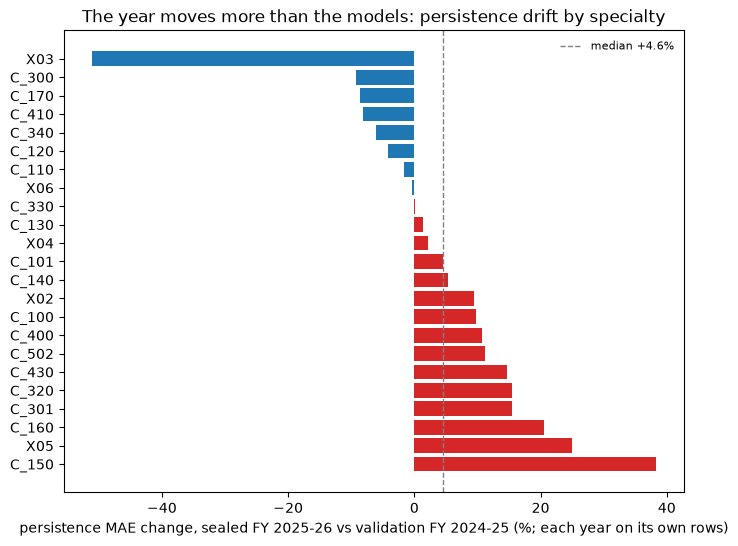

In [17]:
# Goal: fig_sealed_persistence_drift_h1.png - how much harder or easier FY 2025-26 was, per specialty.
drift = (sp_all / sealed[sealed["model"] == "persistence"].set_index("tfunc_code")["val_mae_full"] - 1) * 100
drift = drift.sort_values()
assert len(drift) == 23 and drift.notna().all()   # every scored specialty has both years' persistence MAE
assert round(float(drift.median()), 1) == 4.6     # the documented median year drift; a changed csv trips this

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(np.arange(len(drift)), drift.values, color=np.where(drift.values > 0, "C3", "C0"))
ax.axvline(drift.median(), color="gray", ls="--", lw=1, label=f"median {drift.median():+.1f}%")
ax.set_yticks(np.arange(len(drift)), drift.index); ax.invert_yaxis()
ax.set_xlabel("persistence MAE change, sealed FY 2025-26 vs validation FY 2024-25 (%; each year on its own rows)")
ax.set_title("The year moves more than the models: persistence drift by specialty")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_sealed_persistence_drift_h1.png", "sealed_year_eval.csv",
         "per-specialty % change in persistence MAE from validation to sealed year")
plt.show()

In [18]:
# Goal: output/RESULTS.md - the headline results list; every number below is computed in this cell
# from a stored csv loaded in this run, none typed from memory.
ms = pd.read_csv(PROC / "fl_neural_c110_multiseed.csv")
assert ms.shape == (12, 6), ms.shape
froz = pd.read_csv(PROC / "agent_frozen_summary.csv")
assert froz.shape == (5, 6), froz.shape
RULE_NAMES = {"v1": "capacity", "v2": "redistribution"}   # rule sets named by what they decide;
# the csv keeps the short keys, so an unexpected key in a regenerated csv trips the lookup below

L = ["# RESULTS - headline numbers", "",
     "Generated by `src/13_report_figures.ipynb`; every number is read from a stored csv at build",
     "time. Denominators are stated beside every rate. Figures live in `output/figures/`.", "",
     "## Data",
     f"- Panel: {len(panel):,} provider x specialty x month rows, {panel['month'].nunique()} months, "
     f"{panel['provider_code'].nunique()} providers, {panel['tfunc_code'].nunique()} specialties.",
     f"- National list, era means of monthly values: {natsum.iloc[0]['mean_waiting']/1e6:.2f}M pre-Covid "
     f"(23 months) -> {natsum.iloc[1]['mean_waiting']/1e6:.2f}M post (73 months); >18w share "
     f"{natsum.iloc[0]['mean_pct_gt18']*100:.1f}% -> {natsum.iloc[1]['mean_pct_gt18']*100:.1f}%, "
     f">52w {natsum.iloc[0]['mean_pct_gt52']*100:.2f}% -> {natsum.iloc[1]['mean_pct_gt52']*100:.2f}%.", "",
     "## Forecasting (validation FY 2024-25)",
     f"- C_110 persistence anchor: MAE {fl.loc[fl['model'] == 'naive persistence', 'mae'].iloc[0]:.1f} / "
     f"RMSE {fl.loc[fl['model'] == 'naive persistence', 'rmse'].iloc[0]:.1f} on 1,407 rows - unbeaten by "
     "any level-space model at any grain or horizon (04-09, 12).", "",
     "## Federated learning (validation)",
     f"- Level-space FedAvg fails on non-IID clients: MAE "
     f"{fl.set_index(['regime', 'model']).loc[('full', 'fedavg'), 'mae']:.1f} full / "
     f"{fl.set_index(['regime', 'model']).loc[('post', 'fedavg'), 'mae']:.1f} post (fl_summary_c110.csv).",
     f"- Delta-space repair: fedavg-delta "
     f"{fl.set_index(['regime', 'model']).loc[('full', 'fedavg-delta'), 'mae']:.1f} matches pooled "
     f"{fl.set_index(['regime', 'model']).loc[('full', 'pooled'), 'mae']:.1f} at C_110; across 23 scored "
     f"specialties the fedavg-delta minus pooled MAE gap has median "
     f"{(scale['fedavg_delta_full_mae'] - scale['pooled_full_mae']).median():+.2f} (fl_scaleup_by_specialty.csv).",
     f"- Neural clients (GRU, seed 42): neural FedAvg beats linear FedAvg at "
     f"{int((gap_full < 0).sum())} of 23 specialties (full regime); C_110 neural pooled "
     f"{c110.set_index(['regime', 'model']).loc[('full', 'neural_pooled'), 'mae']:.1f} vs persistence "
     f"{pers:.1f} on 1,401 identical rows (fl_neural_summary.csv).",
     f"- Multi-seed check (seeds {', '.join(str(int(s)) for s in sorted(ms['seed'].unique()))}): "
     f"full-regime C_110 MAE "
     f"{ms[(ms['regime'] == 'full') & (ms['model'] == 'neural_pooled')]['mae'].mean():.1f} +/- "
     f"{ms[(ms['regime'] == 'full') & (ms['model'] == 'neural_pooled')]['mae'].std():.1f} pooled, "
     f"{ms[(ms['regime'] == 'full') & (ms['model'] == 'neural_fedavg')]['mae'].mean():.1f} +/- "
     f"{ms[(ms['regime'] == 'full') & (ms['model'] == 'neural_fedavg')]['mae'].std():.1f} FedAvg - "
     f"all {int((ms[ms['regime'] == 'full']['mae'] < pers).sum())} of 6 full-regime scores below "
     f"persistence {pers:.1f} (fl_neural_c110_multiseed.csv).", "",
     "## Agent rules (frozen 2026-07-30, agent_frozen_summary.csv; csv rule keys: v1 = capacity, "
     "v2 = redistribution)"]
for _, r in froz.iterrows():
    L.append(f"- {RULE_NAMES[r['rule']]} {r['decision']}: {r['n']:,} of 2,337 provider-months "
             f"({r['share_of_2337']*100:.1f}%), median pressure {r['median_pressure']:.3f}, "
             f"median realized 6-month change {r['median_realized_change']:+.1f}.")
out_small = dec[(dec["decision_v2"] == "REDISTRIBUTE_OUT")
                & (dec["icb_code"].map(dec.groupby("icb_code")["provider_code"].nunique()) < 4)]
L += [f"- Receiver reachability: {(m['_merge'] == 'both').mean()*100:.1f}% of 457 OUT months have an "
      f"in-ICB receiver slot; {len(out_small)} of 457 OUT months sit in sub-4-provider ICBs where no "
      "local receiver is arithmetically possible.", "",
      "## Sealed year FY 2025-26 (one shot, sealed_year_eval.csv)",
      f"- C_110 (n=1,407): persistence {sp:.1f} edges neural pooled "
      f"{sc.set_index(['model', 'train_cut']).loc[('neural_pooled', 'final'), 'mae']:.1f}; the "
      "validation neural advantage did not replicate prospectively.",
      f"- Aggregate: neural pooled beats persistence at {int((gaps['neural_pooled'] < 0).sum())} of 23 "
      f"scored specialties, neural FedAvg {int((gaps['neural_fedavg'] < 0).sum())}, linear FedAvg (final) "
      f"{int((gaps['linear_fedavg'] < 0).sum())}.",
      f"- Year drift: per-specialty persistence MAE changed by median {drift.median():+.1f}% vs the "
      f"validation year (range {drift.min():+.1f}% to {drift.max():+.1f}%, 23 specialties)."]
Path("../output/RESULTS.md").write_text("\n".join(L) + "\n", encoding="utf-8")
manifest.append(("RESULTS.md", "all result csvs", "headline results list, generated from stored csvs"))
print("\n".join(L))

# RESULTS - headline numbers

Generated by `src/13_report_figures.ipynb`; every number is read from a stored csv at build
time. Denominators are stated beside every rate. Figures live in `output/figures/`.

## Data
- Panel: 343,441 provider x specialty x month rows, 96 months, 651 providers, 24 specialties.
- National list, era means of monthly values: 4.28M pre-Covid (23 months) -> 6.57M post (73 months); >18w share 13.9% -> 38.8%, >52w 0.05% -> 4.11%.

## Forecasting (validation FY 2024-25)
- C_110 persistence anchor: MAE 153.5 / RMSE 330.1 on 1,407 rows - unbeaten by any level-space model at any grain or horizon (04-09, 12).

## Federated learning (validation)
- Level-space FedAvg fails on non-IID clients: MAE 186.5 full / 228.8 post (fl_summary_c110.csv).
- Delta-space repair: fedavg-delta 154.0 matches pooled 153.8 at C_110; across 23 scored specialties the fedavg-delta minus pooled MAE gap has median -0.08 (fl_scaleup_by_specialty.csv).
- Neural clients (GRU, seed 42): neural Fed

## Provenance manifest

One row per artifact: what it is, which stored csv produced it. `output/README.md` is the figure list for
the paper — anyone can trace any chart back to its source without opening a notebook.

In [19]:
# Goal: output/README.md - the artifact -> source map, written from the manifest built above.
lines = ["# output/ - report artifacts", "",
         "Built by `src/13_report_figures.ipynb` from the stored csvs in `data/processed/` only.",
         "No model, split, band or decision is recomputed here; `data/processed/` remains the single source of truth.",
         "`figures/from_notebooks/` holds every image embedded in the executed notebooks, harvested by",
         "`src/18_extract_figures.ipynb`; its `manifest.csv` maps each file to its notebook and cell.", "",
         "| artifact | source csv | shows |", "|---|---|---|"]
lines += [f"| `{a}` | `{s}` | {w} |" for a, s, w in manifest]
Path("../output/README.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"{len(manifest)} artifacts:")
for a, s, w in manifest:
    print(f"  {a}  <-  {s}")

23 artifacts:
  figures/fig_national_trend.png  <-  rtt_incomplete_panel.csv
  figures/fig_national_longwait_shares.png  <-  rtt_incomplete_panel.csv
  evals/eval_national_pre_post.csv  <-  rtt_incomplete_panel.csv
  evals/eval_specialty_pre_post.csv  <-  rtt_incomplete_panel.csv
  evals/eval_provider_pre_post.csv  <-  rtt_incomplete_panel.csv
  evals/eval_provider_specialty_pre_post.csv  <-  rtt_incomplete_panel.csv
  figures/fig_c110_horizon_mae_by_grain.png  <-  val_horizons_c110.csv + val_horizons_coarse_c110.csv
  evals/eval_c110_persistence_mae_by_month_h1.csv  <-  val_forecasts_c110_public_clients.csv
  evals/eval_c110_provider_mae_h1.csv  <-  val_forecasts_c110_public_clients.csv
  figures/fig_c110_provider_mae_h1.png  <-  val_forecasts_c110_public_clients.csv
  evals/eval_c110_agent_provider_h6.csv  <-  agent_decisions_h6_c110.csv
  evals/eval_c110_agent_icb_h6.csv  <-  agent_decisions_h6_c110.csv
  evals/eval_c110_agent_stress_h6.csv  <-  agent_decisions_h6_c110.csv
  figures